# Backtest del plan conservador: riqueza y UVR

Lee `results/backtest_conservative.csv` (generado con `python -m uvr_loan.backtest`) y muestra dos figuras:

- **Riqueza en UVR:** la riqueza del portafolio dividida por la UVR real, y dividida por la UVR proyectada en cada revisión (tramos punteados).
- **UVR real y proyectada:** la proyección es la que usa la regla para dimensionar el FIC: parte de la UVR del día de la revisión y crece con el escenario de inflación `liquidity_scenario` durante los `rebalance_every` meses siguientes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months, month_to_period
from uvr_loan.config import RESULTS_DIR, load_assumptions
from uvr_loan.inflation import project_uvr, scenarios

cfg = load_assumptions()
bt = cfg["backtest"]
k = bt["rebalance_every"]
scenario = cfg["conservative"]["liquidity_scenario"]
inflation = scenarios(cfg)[scenario]

results = pd.read_csv(RESULTS_DIR / "backtest_conservative.csv")
results["date"] = pd.PeriodIndex(results["period"], freq="M").to_timestamp(how="end").normalize()
results.head()

,month,period,uvr,payment_cop,shortfall,fic,cdt,etf,wealth,review,date
0,0,2016-10,242.5180,0.0,0.0,0.0,6.840000e+08,7.600000e+07,7.600000e+08,True,2016-10-31
1,1,2016-11,242.3866,0.0,0.0,0.0,6.879959e+08,7.173591e+07,7.597318e+08,False,2016-11-30
2,2,2016-12,242.4513,0.0,0.0,0.0,6.920151e+08,7.531061e+07,7.673257e+08,False,2016-12-31
3,3,2017-01,243.1056,0.0,0.0,0.0,6.960578e+08,7.592567e+07,7.719835e+08,False,2017-01-31
4,4,2017-02,244.7496,0.0,0.0,0.0,7.001241e+08,7.431073e+07,7.744348e+08,False,2017-02-28


## UVR proyectada en cada revisión

Un tramo por revisión τ: los meses τ … τ + k, empezando en la UVR real de τ.

In [2]:
uvr_real = results.set_index("month")["uvr"]


def projection(tau: int) -> pd.Series:
    months = range(tau, tau + k + 1)
    values = [uvr_real[tau], *project_uvr(uvr_real[tau], inflation, k)]
    dates = [month_to_period(bt["t0"], m).to_timestamp(how="end").normalize() for m in months]
    return pd.Series(values, index=dates)


projections = [projection(tau) for tau in decision_months(bt)]

## Gráfico

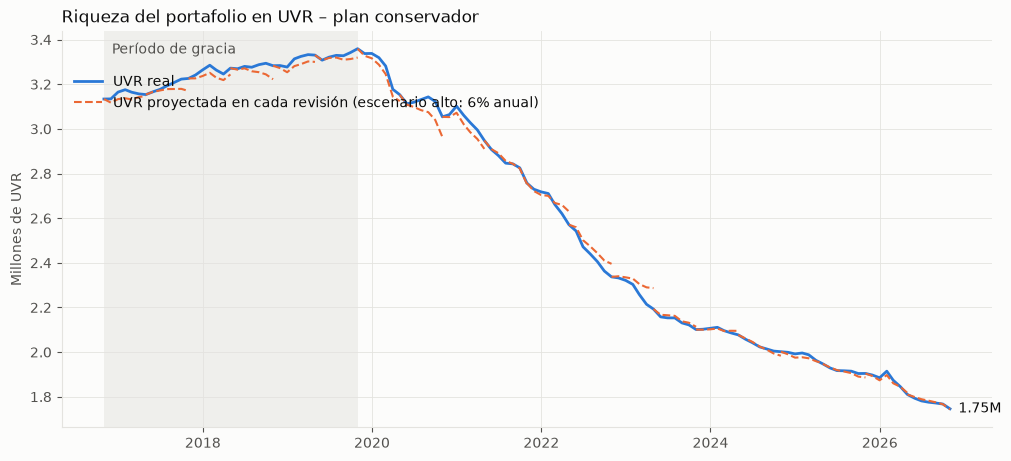

In [3]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
SCENARIO_NAMES = {"base": "base", "high": "alto", "low": "bajo"}
TEXT, TEXT_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": TEXT_2,
        "axes.titlecolor": TEXT,
        "xtick.color": TEXT_2,
        "ytick.color": TEXT_2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "font.size": 10,
    }
)

grace_end = month_to_period(bt["t0"], cfg["loan"]["grace_months"]).to_timestamp(how="end")


def shade_grace(ax):
    ax.axvspan(results["date"].iloc[0], grace_end, color=GRID, alpha=0.5, lw=0)
    ax.text(
        results["date"].iloc[0],
        0.97,
        "  Período de gracia",
        transform=ax.get_xaxis_transform(),
        va="top",
        color=TEXT_2,
    )


# Riqueza en UVR: con la UVR real y con la UVR proyectada en cada revisión
wealth = results.set_index("date")["wealth"]
wealth_uvr_real = wealth / results.set_index("date")["uvr"]

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
shade_grace(ax)
ax.plot(wealth_uvr_real.index, wealth_uvr_real / 1e6, color=BLUE, lw=2, label="UVR real")
for i, p in enumerate(projections):
    p = p[p.index.isin(wealth.index)]
    label = (
        f"UVR proyectada en cada revisión (escenario {SCENARIO_NAMES[scenario]}: {inflation:.0%} anual)"
        if i == 0
        else None
    )
    ax.plot(p.index, wealth[p.index] / p.values / 1e6, color=ORANGE, lw=1.5, ls="--", label=label)
ax.annotate(
    f"{wealth_uvr_real.iloc[-1] / 1e6:,.2f}M",
    (wealth_uvr_real.index[-1], wealth_uvr_real.iloc[-1] / 1e6),
    xytext=(6, 0),
    textcoords="offset points",
    va="center",
    color=TEXT,
)
ax.set_title("Riqueza del portafolio en UVR – plan conservador", loc="left")
ax.set_ylabel("Millones de UVR")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92), labelcolor=TEXT)

plt.show()

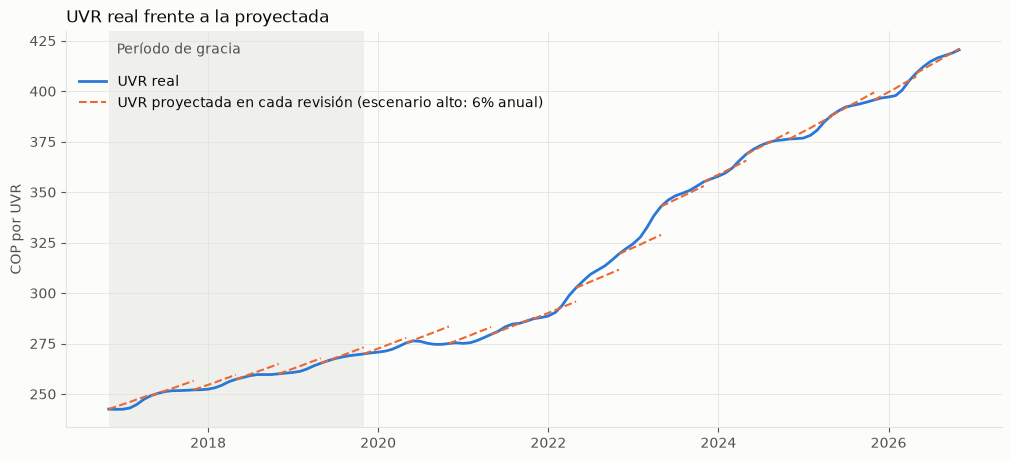

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
shade_grace(ax)
ax.plot(results["date"], results["uvr"], color=BLUE, lw=2, label="UVR real")
for i, p in enumerate(projections):
    label = (
        f"UVR proyectada en cada revisión (escenario {SCENARIO_NAMES[scenario]}: {inflation:.0%} anual)"
        if i == 0
        else None
    )
    ax.plot(p.index, p.values, color=ORANGE, lw=1.5, ls="--", label=label)
ax.set_title("UVR real frente a la proyectada", loc="left")
ax.set_ylabel("COP por UVR")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92), labelcolor=TEXT)

plt.show()